# AlphaFold Structure Analysis and Feature Extraction

This notebook provides an automated pipeline for analyzing and visualizing AlphaFold protein structures (CIF format). 

**Workflow Overview:**
1. **Interactive Visualization:** Renders the full 3D protein structure using `py3Dmol`, color-coded by AlphaFold's pLDDT confidence scores.
2. **Secondary Structure & Confidence Profiling:** Uses `biotite` to compute secondary structural elements (helices, sheets, coils) from 3D coordinates and plots them alongside pLDDT scores.
3. **Feature Extraction:** Identifies contiguous alpha helices, calculates their lengths and mean confidence scores, and summarizes them in a table.
4. **PDB Export & Inspection:** Slices the identified alpha helices from the main structure, exports them as isolated `.pdb` files into a dedicated directory, and visualizes individual structural motifs with atomic side-chain details.


In [1]:
%pip install py3Dmol biopython


Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [17]:
import py3Dmol

with open("fold_tcf4_model_0.cif", "r") as file:
    cif_data = file.read()

view = py3Dmol.view(width=800, height=500)
view.addModel(cif_data, "cif")

# Color by the 'b' property (B-factor/pLDDT). 
# The 'rwb' (red-white-blue) gradient maps 50 to red (low confidence) and 100 to blue (high confidence).
view.setStyle({'cartoon': {'colorscheme': {'prop': 'b', 'gradient': 'rwb', 'min': 50, 'max': 100}}})

view.zoomTo()
view.show()


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [18]:
!pip install biotite matplotlib

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


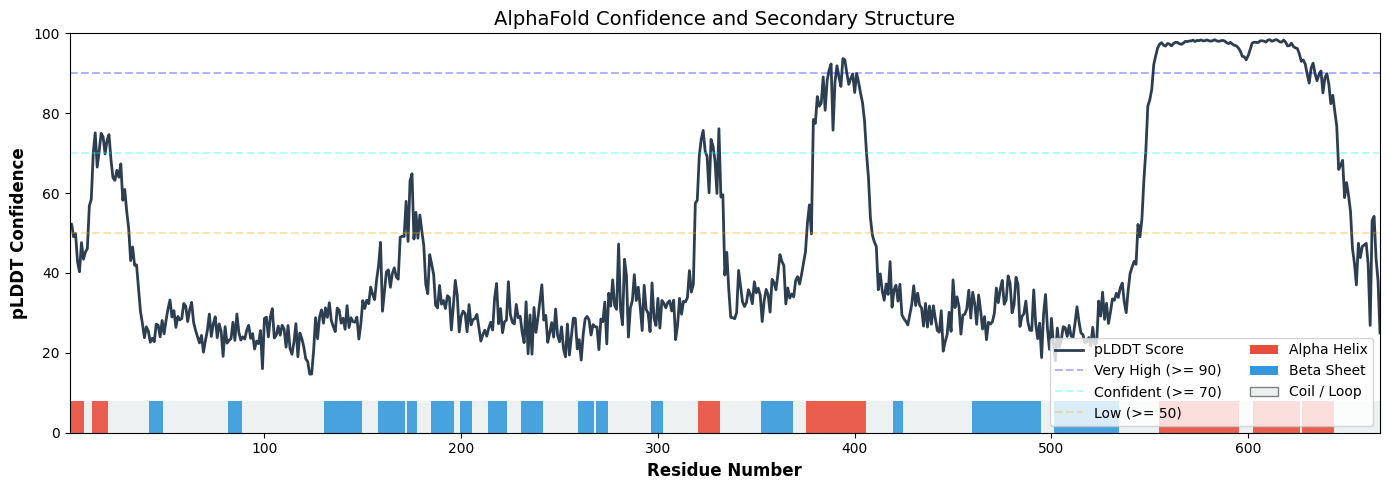

In [21]:
import biotite.structure.io.pdbx as pdbx
import biotite.structure as struc
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings

# Suppress minor Biotite warnings regarding AlphaFold CIF formatting
warnings.filterwarnings("ignore")

# 1. Load the CIF file using the pdbx module
cif_file = pdbx.CIFFile.read("fold_tcf4_model_0.cif")

# FIX: Explicitly request the b_factor column using extra_fields
structure = pdbx.get_structure(cif_file, model=1, extra_fields=["b_factor"])

# 2. Extract pLDDT scores (stored in the B-factor column)
# Filter for C-alpha atoms to get exactly one data point per residue
ca_atoms = structure[structure.atom_name == "CA"]
residues = ca_atoms.res_id
plddt = ca_atoms.b_factor

# 3. Calculate secondary structure from the 3D coordinates
# Returns an array of 'a' (alpha helix), 'b' (beta sheet), or 'c' (coil)
sse = struc.annotate_sse(structure)

# 4. Create the plot
fig, ax = plt.subplots(figsize=(14, 5))

# Plot the pLDDT line
ax.plot(residues, plddt, color='#2c3e50', linewidth=2, label='pLDDT Score')

# Add secondary structure as a color band at the bottom (bottom 8% of the plot)
sse_colors = {'a': '#e74c3c', 'b': '#3498db', 'c': '#ecf0f1'} # Red=Helix, Blue=Sheet, Grey=Coil

for i, res_id in enumerate(residues):
    ax.axvspan(res_id - 0.5, res_id + 0.5, 
               ymin=0, ymax=0.08, 
               color=sse_colors.get(sse[i], '#ecf0f1'), 
               alpha=0.9, lw=0)

# Formatting the axes and labels
ax.set_xlim(residues[0], residues[-1])
ax.set_ylim(0, 100)
ax.set_xlabel("Residue Number", fontsize=12, fontweight='bold')
ax.set_ylabel("pLDDT Confidence", fontsize=12, fontweight='bold')
ax.set_title("AlphaFold Confidence and Secondary Structure", fontsize=14)

# Add standard AlphaFold threshold lines
ax.axhline(90, color='blue', linestyle='--', alpha=0.3, label='Very High (>= 90)')
ax.axhline(70, color='cyan', linestyle='--', alpha=0.3, label='Confident (>= 70)')
ax.axhline(50, color='orange', linestyle='--', alpha=0.3, label='Low (>= 50)')

# Create custom legends for the secondary structure blocks
legend_elements = [
    Patch(facecolor='#e74c3c', label='Alpha Helix'),
    Patch(facecolor='#3498db', label='Beta Sheet'),
    Patch(facecolor='#ecf0f1', edgecolor='gray', label='Coil / Loop')
]

# Combine both legends and place them on the plot
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + legend_elements, loc='lower right', fontsize=10, ncol=2)

plt.tight_layout()
plt.show()


In [22]:
import pandas as pd
import numpy as np

# Variables to track the helices
helices = []
in_helix = False
start_idx = 0

# Iterate through the secondary structure array to find contiguous 'a' (alpha helix) blocks
for i, sec_struct in enumerate(sse):
    if sec_struct == 'a' and not in_helix:
        in_helix = True
        start_idx = i
    elif sec_struct != 'a' and in_helix:
        in_helix = False
        end_idx = i - 1
        
        # Calculate stats for the completed helix
        mean_plddt = np.mean(plddt[start_idx:end_idx + 1])
        
        helices.append({
            'Helix #': len(helices) + 1,
            'Start Residue': residues[start_idx],
            'End Residue': residues[end_idx],
            'Length': end_idx - start_idx + 1,
            'Mean pLDDT': round(mean_plddt, 2)
        })

# Catch the edge case where the protein ends on a helix
if in_helix:
    end_idx = len(sse) - 1
    mean_plddt = np.mean(plddt[start_idx:end_idx + 1])
    helices.append({
        'Helix #': len(helices) + 1,
        'Start Residue': residues[start_idx],
        'End Residue': residues[end_idx],
        'Length': end_idx - start_idx + 1,
        'Mean pLDDT': round(mean_plddt, 2)
    })

# Convert to a pandas DataFrame and display it
df_helices = pd.DataFrame(helices)
display(df_helices)


,Helix #,Start Residue,End Residue,Length,Mean pLDDT
0,1,2,8,7,46.48
1,2,13,20,8,71.79
2,3,321,331,11,69.77
3,4,376,405,30,82.91
4,5,555,595,41,97.73
5,6,603,626,24,97.59
6,7,628,643,16,88.94


In [24]:
import biotite.structure.io.pdb as pdb
import os

# Define and create the output directory
output_dir = "extracted_helices"
os.makedirs(output_dir, exist_ok=True)

saved_files = []

# Iterate through the DataFrame
for index, row in df_helices.iterrows():
    helix_num = int(row['Helix #'])
    start_res = int(row['Start Residue'])
    end_res = int(row['End Residue'])
    
    # Slice the original structure array for residues within this helix
    helix_atoms = structure[(structure.res_id >= start_res) & (structure.res_id <= end_res)]
    
    # Define the output filename and join it with the directory path
    file_name = f"helix_{helix_num}_res_{start_res}_to_{end_res}.pdb"
    file_path = os.path.join(output_dir, file_name)
    
    # Initialize a PDB file object, set the structure, and write to disk
    pdb_file = pdb.PDBFile()
    pdb.set_structure(pdb_file, helix_atoms)
    pdb_file.write(file_path)
    
    saved_files.append(file_path)

# Print a summary of the generated files
print(f"Successfully extracted {len(saved_files)} helices into the '{output_dir}/' directory:")
for f in saved_files:
    print(f" - {f}")


Successfully extracted 7 helices into the 'extracted_helices/' directory:
 - extracted_helices/helix_1_res_2_to_8.pdb
 - extracted_helices/helix_2_res_13_to_20.pdb
 - extracted_helices/helix_3_res_321_to_331.pdb
 - extracted_helices/helix_4_res_376_to_405.pdb
 - extracted_helices/helix_5_res_555_to_595.pdb
 - extracted_helices/helix_6_res_603_to_626.pdb
 - extracted_helices/helix_7_res_628_to_643.pdb


In [29]:
import py3Dmol

# Ensure there is at least one file in the list
if saved_files:
    # Pick the first extracted helix
    helix_path = saved_files[0]
    
    # Read the PDB file contents
    with open(helix_path, "r") as file:
        pdb_data = file.read()
        
    print(f"Visualizing: {helix_path}")
    
    # Initialize the viewer
    view = py3Dmol.view(width=800, height=400)
    view.addModel(pdb_data, "pdb")
    
    # Set the style: a cyan cartoon ribbon for the backbone, and sticks for the side chains
    view.setStyle({'cartoon': {'color': 'cyan'}, 'stick': {'radius': 0.15}})
    
    # Zoom to fit the helix and render
    view.zoomTo()
    view.show()
else:
    print("No extracted helices found. Please run the extraction step first.")


Visualizing: extracted_helices/helix_1_res_2_to_8.pdb


3Dmol.js failed to load for some reason. Please check your browser console for error messages.